# Projet : POKEDEX
objectif : créer une application Python offrant les fonctionnalités d'un pokédex

Les fonctionnalités à implémenter : 
- analyse et classifier les Pokémons
- prédire certaines propriétés

Jeu de données : 
- fichier csv "pokemon" (caractéristiques) :  https://www.kaggle.com/code/melearning-with-pokemon-predicting-legend/input?select=pokemon.csv
- banque d'image pokémon (1er gen) :  https://www.kaggle.com/datasets/mikoajkolman/pokemon-images-first-generation17000-files

### Rendue
- Notebook/code
- rapport : 
    - méthodo. adoptée
    - différentes méthodes et modèles testés
    - résultats + analyses/interprétations
    - limites approche + améliorations possibles

In [2]:
print("Hello, World!")

Hello, World!


In [3]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [4]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [5]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.


In [6]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.


## Niveau 1 : Données tabulaires

But : 
clustering : identifier les groupes + interprédation
statistiques de base => légendaire ou non + type du pokémon

A implémenter dans l'affichage: 
- groupe du Pokémon
- légendaire ou non

Tester plus. méthodes et justifier choix du modèle (comparaison du modèle)

Donnée 'pokémon.csv'

| Features name | Features' type |
| - | - |
|# | Float|
| Name | String 
Type 1 | String 
Type 2 | String 
HP | Float
Attack | Float
Defense | Float
Sp. Atk | Float
Sp. Def | Float
Speed | Float
Generation | Float
Legendary | Bool

[ Méthode à développer d'après Claude.com ]
1. Prétraitement des données : 
- entrées : stats
- cibles : types / légendaire
- séparation des données
2. Clustering
- différentes méthodes d'après stats
- choix nombre de clusters
- interprétation clusters (légendaire/types)
3. Classification 
4. Comparaison



#### Clustering

In [7]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
# Importation des données

data = pd.read_csv('pokemon.csv', index_col="#")


# Prétraitement
stats = ["HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed"]
y_leg, y_type = data["Legendary"].astype("int8"), data["Type 1"]

# Normalisation des données
scaler = StandardScaler()
X = scaler.fit_transform(data[stats])


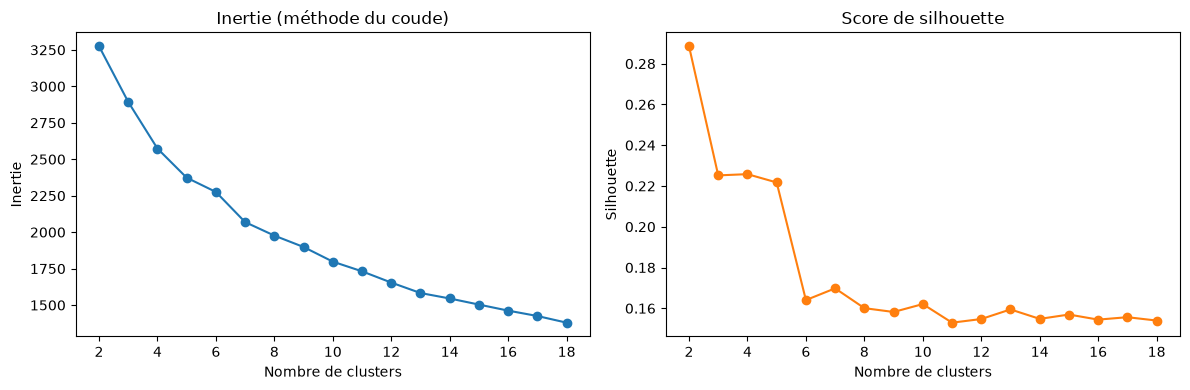

In [8]:
# K-means clustering

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

# Détermination du nombre de clusters optimal
inertias = []
score = []

for k in range(2, 19):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X)
    inertias.append(kmeans.inertia_) # Méthode du coude 
    score.append(silhouette_score(X, kmeans.fit_predict(X))) # Score de silhouette


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(2, 19), inertias, marker="o")
axes[0].set_title("Inertie (méthode du coude)")
axes[0].set_xlabel("Nombre de clusters")
axes[0].set_ylabel("Inertie")

axes[1].plot(range(2, 19), score, marker="o", color="tab:orange")
axes[1].set_title("Score de silhouette")
axes[1].set_xlabel("Nombre de clusters")
axes[1].set_ylabel("Silhouette")

plt.tight_layout()
plt.show()

D'après la méthode du coude et de la silhoutte, on repère que le nombre optimal de cluster est soit de 4 ou de 6

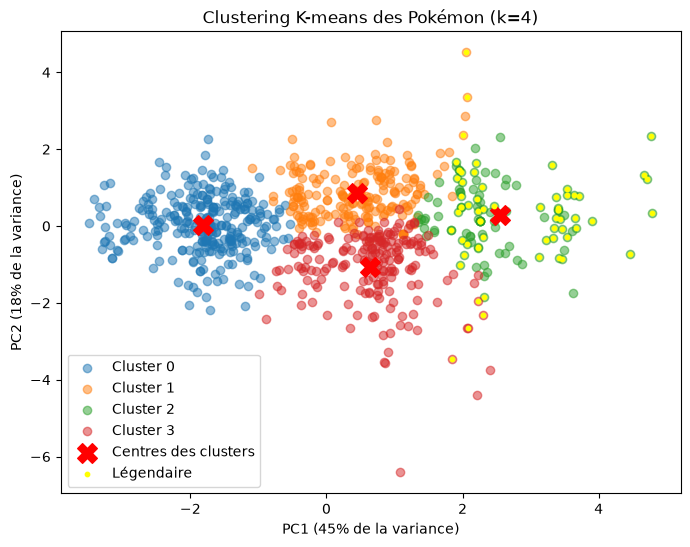

In [9]:
# Clustering avec le nombre de clusters optimal (k=4)
from sklearn.decomposition import PCA

kmeans = KMeans(n_clusters=4, random_state=42)
kmeans.fit(X)
labels = kmeans.predict(X)

# Projection sur les axes principaux
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)                       # X doit être standardisé
centres_pca = pca.transform(kmeans.cluster_centers_)

# Visualisation des clusters
plt.figure(figsize=(8, 6))
for c in range(4):
    plt.scatter(X_pca[labels ==c, 0], X_pca[labels ==c, 1], label=f"Cluster {c}", alpha = 0.5)
plt.scatter(centres_pca[:, 0], centres_pca[:, 1], c='red', marker='X', s=200, label='Centres des clusters')
plt.scatter(X_pca[y_leg == 1, 0], X_pca[y_leg == 1, 1], c="yellow", label="Légendaire", s = 10)
plt.title("Clustering K-means des Pokémon (k=4)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} de la variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} de la variance)")
plt.legend()
plt.show()



In [10]:
# Analyse et interprétation des clusters

#Création d'un tableau récapitulatif des clusters 

data_clusters = data.copy()

# Ajout d'une colonne "Cluster" avec le numéro de cluster de chaque Pokémon

data_clusters["Cluster"] = labels

# Affichage du nombre de Pokémon par cluster
# Value counts compte combien de fois chaque valeur de cluster apparaît
# Sort index classe les résultats par ordre croissant de clusterts dans l'ordre des numéros de clusters

print(data_clusters["Cluster"].value_counts().sort_index())


Cluster
0    283
1    202
2    115
3    200
Name: count, dtype: int64


In [14]:
# Intéprétation des axes pca - poids associé à chaque stat

poids = pd.DataFrame(pca.components_.T, index=stats, columns=["PC1", "PC2"])
print(poids.round(2))

# Calcul des stats moyennes pour chaque cluster ( pour interpréter les caractéristiques principales des clusters)

# Regrouper tous les poké qui appartiennent à un même cluster et calculer la moyenne des stats pour chaque cluster 
moyennes_clusters = data_clusters.groupby("Cluster")[stats].mean()

# Arrondir à deux décimales

moyennes_clusters.round(2)

          PC1   PC2
HP       0.39 -0.08
Attack   0.44  0.01
Defense  0.36 -0.63
Sp. Atk  0.46  0.31
Sp. Def  0.45 -0.24
Speed    0.34  0.67


,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed
Cluster,,,,,,
0,50.11,53.98,51.89,48.06,49.21,49.45
1,69.29,84.31,65.91,83.52,73.04,94.62
2,94.30,114.02,94.57,117.65,103.69,95.45
3,81.92,88.92,101.00,71.26,84.58,52.68


Interprétation : 

- projection pc1 : valeur de 0.34 à 0.46 => moyenne globale des stats donc l'axe est un indicateur de la puissance globale du pokemon
- projection pc2 : valeur de -0.63 (defense) à 0.67 (speed) => indicateur sur le style de combat du pokemon offensif ou defensif
-----
- Cluster 0 = Pokémon aux statistiques globalement faibles ( toutes les moyennes aux alentours de 50 )
- Cluster 1 = Pokémon rapides
- Cluster 2 = Statistiques globalement élevées ( meilleurs moyennes sauf en défense ), Pokémon particulièrement offensifs ( attaque et attaque spéciale +++ )
- Cluster 3 = Pokémon défensifs

### Classification supervisée

In [ ]:
# Classification supervisée
# Pokémon légendaire ou non légendaire ?

X_leg = data[stats]
#X contient les 6 stats de chaque pokémon
Y_leg = data["Legendary"].astype("int")
#Y contient la réponse (1 si légendaire, 0 sinon)

print(X_leg.shape)
print(Y_leg.shape)

(800, 6)
(800,)


In [ ]:
# Sépare les données pour entraînement puis test
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X_leg, Y_leg, test_size=0.2, random_state=42,
    stratify=Y_leg
)
# Stratify sert à conserver approximativement la même proportion de poké légendaires et non légendaires dans les deux ensembles (train et test)

print(X_train.shape)
print(X_test.shape)

(640, 6)
(160, 6)


##### Modèle KNN

In [ ]:
# Import et entraînement du modèle KNN à 3 voisins
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_neighbors=3)

model.fit(X_train, Y_train)

KNeighborsClassifier(n_neighbors=3)

In [ ]:
model.score(X_test, Y_test)

0.93125

In [ ]:
# Voir les prédictions que le modèle a réellement faites
Y_pred = model.predict(X_test)
print(Y_pred)

[0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0
 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 1 0 0 0 0 0 0 0]


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

#On applique la normalisation sur les données d'entraînement puis on applique cette même normalisation aux données de test
# Il est important de séparer les données avant de normaliser, sinon les données de test influencent la normalisation ( = fuite de données)

In [ ]:
# on fait un KNN avec trois voisins et normalisations pour comparer au KNN à 3 voisins sans normalisation

model_scaled_3 = KNeighborsClassifier(n_neighbors=3)

model_scaled_3.fit(X_train_scaled, Y_train)
model_scaled_3.score(X_test_scaled, Y_test)


0.93125

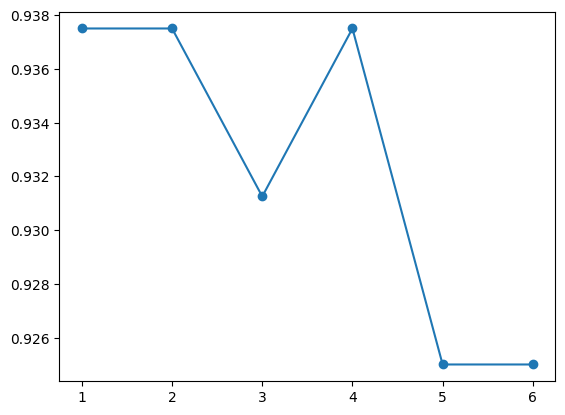

In [ ]:
# Variation du k sur données normalisées

score_k = []
for k in range(1,7):
    model_scaled = KNeighborsClassifier(n_neighbors=k)

    model_scaled.fit(X_train_scaled, Y_train)
    score_k.append(model_scaled.score(X_test_scaled, Y_test))

plt.plot(range(1,7), score_k, marker='o')



Nous avons testé trois modèles KNN pour prédire si un Pokémon est légendaire ou non à partir de ses statistiques de combat. Nous avons modifié deux paramètres : des données normalisées ou non, et le nombre de voisins ( 3 ou 6). Les paramètres ont été modifiés un par un afin de pouvoir observer leur effet sur les résultats.

Observations suite aux tests KNN :

1. La normalisation n'a pas modifié l'accuracy pour le KNN à 3 voisins
2. Le passage de 3 à 6 voisins a légèrement diminué l'accuracy ( de 93,125% à 92,5%)


In [ ]:
# Combien de Pokémon sont réellement légendaires et combien ne le sont pas parmi nos 160 Pokemon de test ?
Y_test.value_counts()

Legendary
0    147
1     13
Name: count, dtype: int64

Limites de l'accuracy : 
Nous avons compté le nombre de Pokemon légendaires et non-légendaires dans nos données de test pour vérifier leur répartition.
En effet, un modèle qui prédirait systématiquement un Pokemon non-légendaire obtiendrait une accuracy de 91,875%. 
Donc l'accuracy seule ne sufit pas pour évaluer la qualité de notre modèle. Il faut encore vérifier s'il est capable de reconnaître les Pokemon légendaires.

In [ ]:
# Prédictions du modèle KNN à 3 voisins et normalisation
Y_pred_scaled_3 = model_scaled_3.predict(X_test_scaled)
print(Y_pred_scaled_3)

[0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0
 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 1 0 0 0 0 0 0 0]


In [ ]:
# On crée un tableau contenant les vraies réponses et les prédictions pour faire la comparaison

comparaison=pd.DataFrame({ "Réel":Y_test, "Prédit":Y_pred_scaled_3})

comparaison

,Réel,Prédit
#,,
250,0,0
129,0,0
564,0,0
342,0,0
786,0,0
...,...,...
96,0,0
194,0,0
699,0,0


In [ ]:
# On compte les bonnes et mauvaises prédictions

comparaison.groupby("Réel")["Prédit"].value_counts()

Réel  Prédit
0     0         143
      1           4
1     0           7
      1           6
Name: count, dtype: int64

Nous venons de compter "manuellement" les bonnes et mauvaises précisions de notre modèle KNN. Mais il existe l'outil de la matrice de confusion pour faire la même chose plus simplement. Nous allons donc tenter d'obtenir les mêmes résultats à l'aide de la matrice de confusion.

In [ ]:
# matrice de confusion du modèle KNN.

from sklearn.metrics import confusion_matrix
confusion_matrix(Y_test, Y_pred_scaled_3)

array([[143,   4],
       [  7,   6]])

Interprétation :

- 143 pokemon non légendaires effectivement reconnus
- 6 pokemon légendaires effectivement reconnus
- 4 pokemon non légendaires prédits comme légendaires
- 7 pokemon légendaires non reconnus

Accuracy totale = 93,125% ( 149/160 )
Reconnaissance des Pokemon non-légendaires = 97,28% ( 143/147 )
Reconnaissance des Pokemon légendaires = 46,15% ( 6/13 )
 
Finalement, malgré une accuracy de 93,125%, on se rend compte le modèle ne reconnaît même pas la moitié des Pokemon légendaires.
Donc l'accuracy seule ne suffit pas pour évaluer les performances d'un modèle, notamment dans le cas de classes déséquilibrées comme c'est le cas ici.

#### Arbre de décision
COmparaison avec d'autres méthodes
--> Méthode de l'arbre de décision 

In [ ]:
# Import et entraînement de l'arbre de décision

from sklearn.tree import DecisionTreeClassifier
arbre=DecisionTreeClassifier(max_depth=4, random_state=42)

arbre.fit(X_train, Y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

In [ ]:
print("Accuracy:",arbre.score(X_test,Y_test))
print("Profondeur:", arbre.get_depth())
print("Nombre de feuilles:", arbre.get_n_leaves())

Accuracy: 0.925
Profondeur: 4
Nombre de feuilles: 12


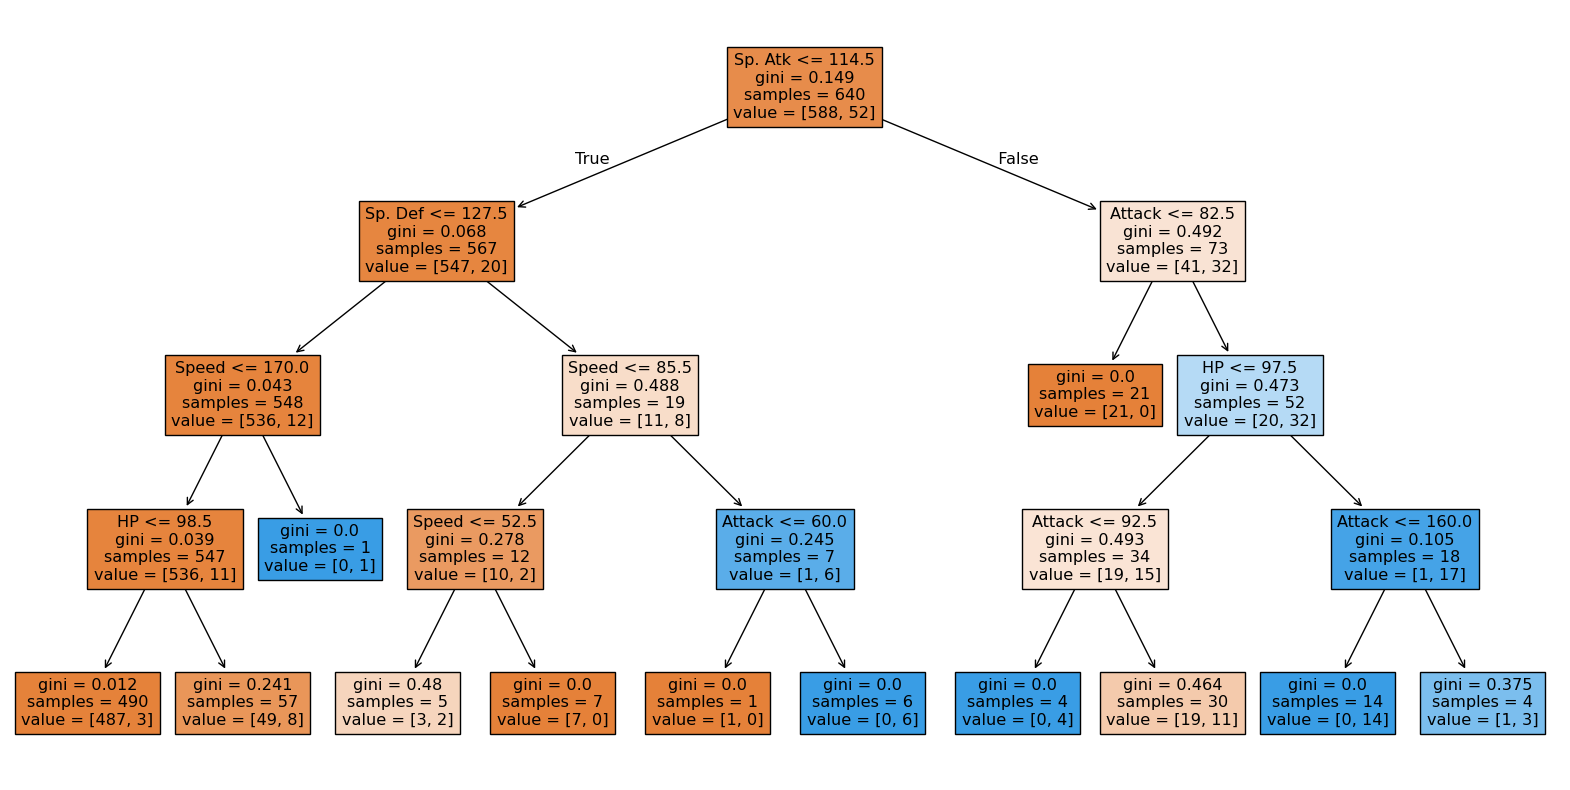

In [ ]:
# Visualisons l'arbre de décision construit

from sklearn.tree import plot_tree
plt.figure(figsize=(20,10))
plot_tree(arbre, feature_names=stats, filled=True)
plt.show()

In [ ]:
# Test de l'influence de la profondeur de l'arbre de décision sur les performances

score_train=[]
score_test=[]

for k in range (1,16):
    arbre_k=DecisionTreeClassifier(max_depth=k, random_state=42)
    arbre_k.fit(X_train, Y_train)

    score_train.append(arbre_k.score(X_train, Y_train))
    score_test.append(arbre_k.score(X_test, Y_test))

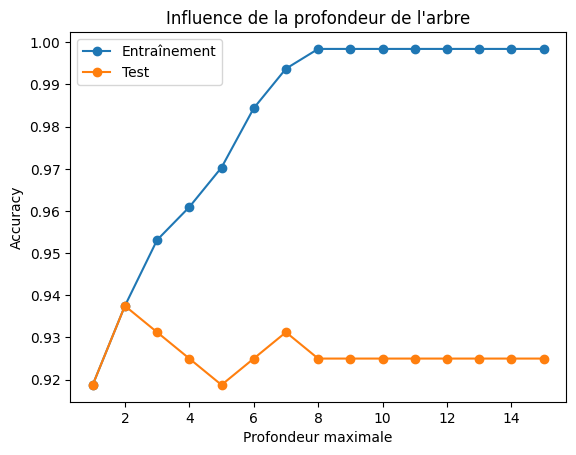

In [ ]:
#Tracé de l'évolution de l'accuracy en fonction de la profondeur de l'arbre

plt.plot(range(1, 16), score_train, marker='o', label="Entraînement")
plt.plot(range(1, 16), score_test, marker='o', label="Test")

plt.xlabel("Profondeur maximale")
plt.ylabel("Accuracy")
plt.title("Influence de la profondeur de l'arbre")
plt.legend()
plt.show()

Interprétation :

- L'accuracy sur les données d'entraînement augmente avec la profondeur, jusqu'à atteindre 100% ou presque
- L'accuracy sur les donées de test augmente jusqu'à atteindre son max pour une profondeur de 2, puis décroit.

--> L'écart entre les deux augmente et met en évidence le phénomène de sur-entraînement

Construction de la matrice de confusion de l'arbre de décision

In [ ]:
# prédictions de l'arbre de décision
Y_pred_arbre = arbre.predict(X_test)

# matrice de confusion de l'arbre de décision
from sklearn.metrics import confusion_matrix
confusion_matrix(Y_test, Y_pred_arbre)

array([[145,   2],
       [ 10,   3]])

Interprétation :

- 145 Pokémon normaux ont été correctement reconnus.
- 2 Pokémon normaux ont été déclarés légendaires.
- 10 Pokémon légendaires ont été déclarés normaux.
- trois. Pokémon légendaires ont été correctement reconnus.

On voit donc que notre arbre de décision a une bonne accuracy de 92,5%, mais qu'il ne reconnaît que 3 Pokémon légendaires sur les 13 réellement présents.
Il semble donc efficace pour reconnaître les Pokémon non légendaires, mais beaucoup moins efficace pour reconnaître les légendaires.

Troisième méthode : forêt aléatoire

In [ ]:
# import de la forêt aléatoire depuis scikit-learn

from sklearn.ensemble import RandomForestClassifier

In [ ]:
# création de la forêt aléatoire

foret = RandomForestClassifier(n_estimators=200, random_state=42, oob_score=True)

foret.fit(X_train, Y_train)

RandomForestClassifier(n_estimators=200, oob_score=True, random_state=42)

In [ ]:
# évaluation de notre forêt aléatoire
# le score OOB correspond à une estimation des perfs du modèle sur des données qui n'ont pas été utilisées par certains arbres lors de l'entraînement.

print("Accuracy:",foret.score(X_test,Y_test))
print("Score OOB :",foret.oob_score_)

Accuracy: 0.925
Score OOB : 0.953125


Comparaison de l'accuracy des trois méthodes utilisées jusque là :

- KNN (k=3) -> accuracy = 93,125%
- Arbre de décision (depth = 4) -> accuracy = 92,5%
- Forêt aléatoire (200 arbres) -> accuracy = 92,5%

On note que les résultats obtenus par les trois méthodes sont globalement proches, le KNN obtient neanmoins une accuracy légèrement supérieure sur le jeu de test.

On va maintenant créer une matrice de cpnfusion pour voir quels pokémon le modèle a mal classés.

In [ ]:
# prédictions de notre forêt aléatoire
Y_pred_foret = foret.predict(X_test)

In [ ]:
# import de la matrice de confusion depuis scikit-learn
from sklearn.metrics import confusion_matrix
confusion_matrix(Y_test, Y_pred_foret)

# avec Y_test les vraies réponses et Y_pred_foret les prédictions de notre modèle, on peut voir combien de Pokémon ont été correctement classés comme légendaires ou non légendaires, et combien ont été mal classés.

array([[145,   2],
       [ 10,   3]])

Interprétation 

La forêt aléatoiore a la même matrice de confusion que l'arbre de décision :

- 145 Pokémon normaux ont été correctement reconnus.
- 2 Pokémon normaux ont été déclarés légendaires.
- 10 Pokémon légendaires ont été déclarés normaux.
- trois. Pokémon légendaires ont été correctement reconnus.

De la même façon que pour l'arbre de décision, on voit que notre forêt a une bonne accuracy de 92,5%, mais qu'elle ne reconnaît que 3 Pokémon légendaires sur les 13 réellement présents.
Elle semble donc efficace pour reconnaître les Pokémon non légendaires, mais beaucoup moins efficace pour reconnaître les légendaires.

Effectuons une validation croisée à 5 plis afin de comparer nos modèles d'une autre façon

In [ ]:
# Import de la validation croisée depuis scikit-learn
from sklearn.model_selection import cross_val_score

In [ ]:
scores_arbre = cross_val_score(arbre, X_train, Y_train, cv=5)
scores_arbre

array([0.953125 , 0.9453125, 0.9296875, 0.90625  , 0.9140625])

In [ ]:
import numpy as np
print("Moyenne des scores de validation croisée pour l'arbre de décision :", np.mean(scores_arbre))
print("Écart-type des scores de validation croisée pour l'arbre de décision :", np.std(scores_arbre))

Moyenne des scores de validation croisée pour l'arbre de décision : 0.9296875
Écart-type des scores de validation croisée pour l'arbre de décision : 0.017815241017174032


In [ ]:
scores_foret = cross_val_score(foret, X_train, Y_train, cv=5)
scores_foret

array([0.9609375, 0.9609375, 0.9296875, 0.9375   , 0.921875 ])

In [ ]:
print("Moyenne des scores de validation croisée pour la forêt aléatoire :", np.mean(scores_foret))
print("Écart-type des scores de validation croisée pour la forêt aléatoire :", np.std(scores_foret))

Moyenne des scores de validation croisée pour la forêt aléatoire : 0.9421875
Écart-type des scores de validation croisée pour la forêt aléatoire : 0.016086922095292187


Pour la validation croisée du modèle KNN, c'est un peu différent à cause de la normalisation qui doit être effectuée à partir des données d'entraînement puis appliquée aux données de validation. Il faut donc effectuer cette opération 5 fois (= 1 fois pour chaque pli ). On utilise pour ça l'outil "pipeline" de sklearn qui sert à rassembler les transformations.

In [ ]:
from sklearn.pipeline import Pipeline

knn_pipeline = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=3))])

In [ ]:
scores_knn = cross_val_score(knn_pipeline, X_train, Y_train, cv=5)
scores_knn

array([0.9296875, 0.9453125, 0.9609375, 0.9375   , 0.921875 ])

In [ ]:
print("Moyenne des scores de validation croisée pour le modèle KNN :", np.mean(scores_knn))
print("Écart-type des scores de validation croisée pour le modèle KNN :", np.std(scores_knn))

Moyenne des scores de validation croisée pour le modèle KNN : 0.9390625
Écart-type des scores de validation croisée pour le modèle KNN : 0.013441133229754104


Résultats de la validation croisée à 5 plis :

- Moyenne/Écart-type de l'accuracy pour le KNN = 0.9390625/0.0134411
- Moyenne/Écart-type de l'accuracy pour l'arbre de décision = 0.9296875/0.0178152
- Moyenne/Écart-type de l'accuracy pour la forêt aléatoire = 0.9421875/0.0160869

La validation croisée présnete des résultats assez proches pour les trois modèles, il est donc nécéssaire de prendre en compte d'autres éléments et notamment les matrices de confusion.


Comparaison des trois matrices de confusion :

Le modèle KNN reconnaît 6 pokemon légendaires sur 13 tandis que les modèles de l'arbre de décision et de la forêt aléatoire en reconnaissent seulement 3 sur 13. À l'inverse, ces derniers reconnaissent davantage de pokémon non légendaires.

Étant donné que notre objectif est la reconnaissance des Pokémon légendaires, le modèle KNN semble être plus adapté même si ses performances restent limitées.

## Niveau 2 : Classification à partir d'images

But : dvlper modèle Ml pour identifier type d'un Pokémon à partir d'une image

Image d'un pokemon => le/les type(s)


## Niveau 3 : Pokédex complet

But : application Pokédex complet

Implémentations : 
- niveau 1
- niveau 2
- fonctionnalités trie par type
- utilisation caméra ordi : image de pokémon

### Application

- Voir dossier App et lancer fichier pokedex.py

Fonctionnalitées :
- Affichage liste des pokémons
- Recherche par nom
- Trie par type, génération, légendaire
- Boutons pour différents onglets : Home, Infos, Predictions, ...


Voir quelques informations nécessaire dans l'application